In [1]:
import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm

In [3]:
os.chdir('/Users/eochoa/Documents/Research_Ambuj/ASD/Code/')

In [4]:
import pandas as pd
from utils import *
from logistic_utils import *
from GP_utils import *
#from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

In [5]:
hsi_df = pd.read_csv('/Users/eochoa/Downloads/GHISACONUS_2008_001_speclib.csv', skiprows=6)
hsi_df_filter = hsi_df.query('Image == "EO1H0440332012234110KD_SGS_01"')#.reset_index(drop=True)
hsi_df_filter['Crop_num'] = (hsi_df['Crop'] == 'rice') * 1
df_desc = hsi_df_filter.loc[:, ['long','lat','X803', 'X1629', 'X2174']].reset_index(drop=True)
df_yield = hsi_df_filter.loc[:, ['Crop_num']].reset_index(drop=True)

idx = np.random.choice(99,99,replace=False)
df_desc = df_desc.iloc[idx,:].reset_index(drop=True)
df_yield = df_yield.iloc[idx].reset_index(drop=True)


In [40]:
T = 99
n_row = 99
cutoff = 5
prob_dict = {
    "m": n_row,
    "noise": 0.01,
    "d": cutoff
  }
prob = GP_discover(**prob_dict)
x = df_desc.to_numpy()
x = (x - x.mean(0))+1
x = normalize(x, axis=0, norm='l2')
prob.x = x
prob.y = df_yield.iloc[:, 0].values #/ 100.0

In [7]:
x.mean(0)

array([0.10040774, 0.09952525, 0.01513313, 0.03676088, 0.04421537])

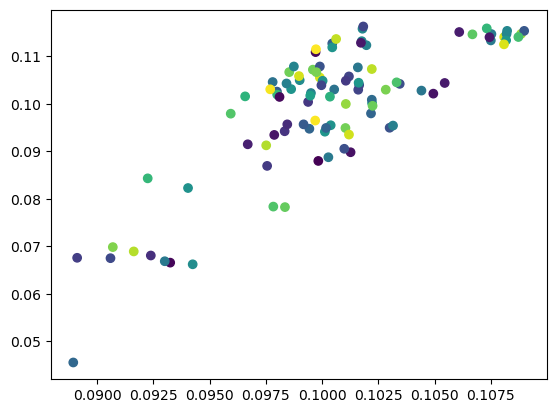

In [8]:
y = np.random.rand(99)
neigh = NearestNeighbors(radius=0.02).fit(x)
nn = neigh.radius_neighbors(x, return_distance=False)
y_nn = np.zeros(99)
for i in range(99):
    y_nn[i] = y[nn[i]].mean()
plt.scatter(x[:,0], x[:,1], c=y_nn)

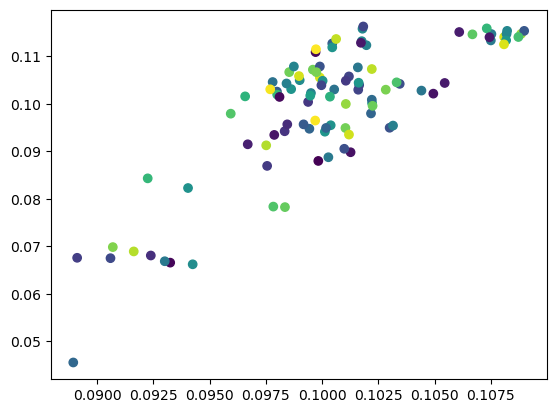

In [9]:
plt.scatter(x[:,0], x[:,1], c=y_nn)

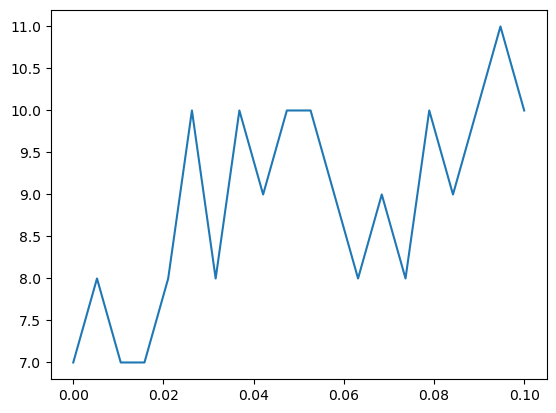

In [10]:
max_regret = np.zeros(20)
r_list = np.linspace(0,.1,20)
for i, r in enumerate(r_list):
    solver_2 = TS_GP_Rand(prob, r = r)#, **algo_params)
    max_regret[i] = solver_2.run(T=T, M=0)[0].max()
    
plt.plot(r_list, max_regret)

In [41]:
algos_dict = {
  'Random': [GP_solver, {}, 10, 'Random', 'y'],
  'Oracle_logistic': [Oracle_logistic, {}, 10, 'Oracle_logistic', 'darkblue'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'mediumblue'],
  'G_logistic': [G_logistic, {}, 10, 'G_logistic', 'blue'],
    'IDS_logistic': [IDS_logistic, {}, 10, 'IDS_logistic', 'red']
    
  #'G_logistic_2': [G_logistic, {'r':.08}, 10, 'G_logistic_2 = 0.07', 'royalblue'],
  
  #'Oracle_GP': [TS_GP, {}, 10, 'Oracle_GP', 'darkgreen'],
  #'TS_GP_True': [TS_GP_True, {}, 10, 'TS_GP_True', 'y'],
  #'G_GP': [TS_GP_Rand, {}, 10, 'G_GP', 'green']
  #'G_GP_2': [TS_GP_Rand, {'r':.06}, 10, 'G_GP_2 r = 0.06', 'limegreen']
  #'Multi_G_GP': [Multi_G_GP, {}, 10, 'Multi_G_GP', 'y']#,
  
}

In [42]:
reg_list = {algo:[] for algo in algos_dict}
#tau_list = {algo:[] for algo in algos_dict}

for trial_idx in trange(10):
    # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, _ = solver.run(T)[:2]
        #act_list[algo].append(getattr(solver, "logistic_discover"))
        #act_list[algo].append(t_prob.actions)
        # print(prob.rewards)
        reg_list[algo].append(reg)
        #tau_list[algo].append(tau)

100%|███████████████████████████████████████████| 10/10 [00:11<00:00,  1.18s/it]


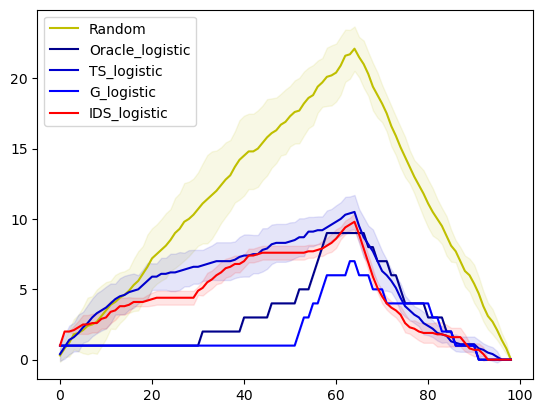

In [43]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

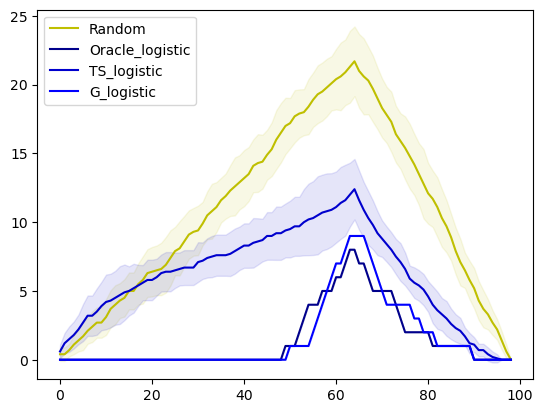

In [16]:
your_keys = ['Random',
             'Oracle_logistic',
             'TS_logistic',
             'G_logistic']#,
             #'G_logistic_2']#,
             #'Oracle_GP',
             #'G_GP',
             #'G_GP_2']

algos_dict_2 = {key: algos_dict[key] for key in your_keys}

for algo in algos_dict_2:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

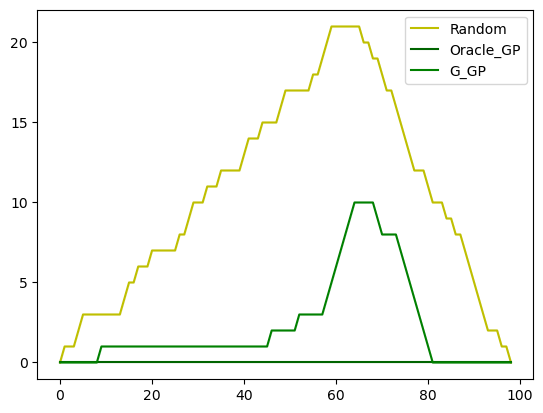

In [15]:
your_keys = ['Random',
             #'Oracle_logistic',
             #'TS_logistic',
             #'G_logistic',
             #'G_logistic_2',
             'Oracle_GP',
             'G_GP']
             #'G_GP_2']

algos_dict_2 = {key: algos_dict[key] for key in your_keys}

for algo in algos_dict_2:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [17]:
S = 10
res_list = {algo:defaultdict(list) for algo in algos_dict}
reg_list = {algo:[] for algo in algos_dict}

for algo, algo_setup in tqdm(algos_dict.items()):
    for M in np.arange(1,65):
        taus = np.zeros(S)
        for trial_idx in range(S):
            t_prob = deepcopy(prob)
          
            algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                    # print(algo_func)
            if not trial_idx < algo_N_trials:
                continue
            solver = algo_func(t_prob, **algo_params)
            reg, rw, taus[trial_idx] = solver.run(T=T, M=M)
            res_list[algo]['regret'].append(reg)
            res_list[algo]['rw'].append(rw)
            res_list[algo]['tau'].append(taus[trial_idx])
        
        #res_list[algo]['regret'].append(np.mean(reg_list[algo], axis = 0)[:T]) 
        res_list[algo]['M'].append(M)
        res_list[algo]['tau_mean'].append(taus.mean())
        res_list[algo]['tau_std'].append(taus.std())
        

100%|█████████████████████████████████████████████| 5/5 [06:04<00:00, 72.85s/it]


In [ ]:
['Random',
  'Oracle_logistic',
  'TS_logistic',
  'G_logistic',
    'IDS_logistic']

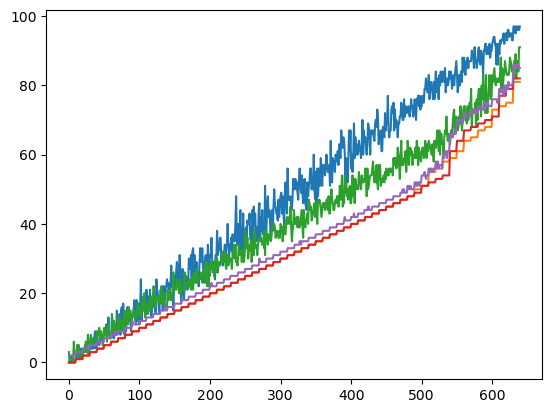

In [37]:
plt.plot(np.array(res_list['Random']['tau']))
plt.plot(np.array(res_list['Oracle_logistic']['tau']))
plt.plot(np.array(res_list['TS_logistic']['tau']))
plt.plot(np.array(res_list['G_logistic']['tau']))
plt.plot(np.array(res_list['IDS_logistic']['tau']))

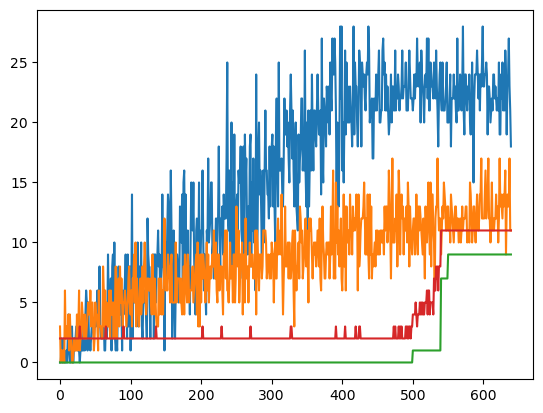

In [41]:
plt.plot(np.array([x.max() for x in res_list['Random']['regret']]))
#plt.plot(np.array([x.max() for x in res_list['Oracle_logistic']['regret']]))
plt.plot(np.array([x.max() for x in res_list['TS_logistic']['regret']]))
plt.plot(np.array([x.max() for x in res_list['G_logistic']['regret']]))
plt.plot(np.array([x.max() for x in res_list['IDS_logistic']['regret']]))

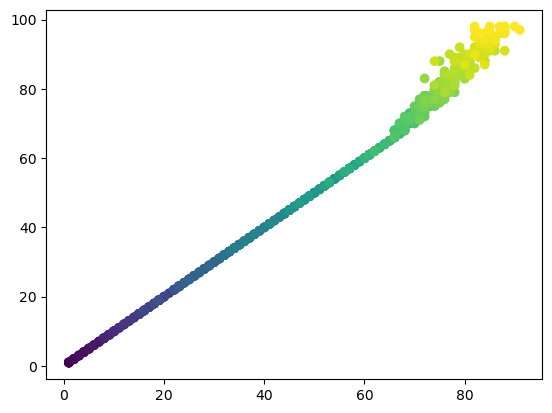

In [38]:
plt.scatter(np.array([x.max() for x in res_list['Random']['regret']]) + np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten(),
            (np.array(res_list['Random']['tau']) + 1),
           c=np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten())

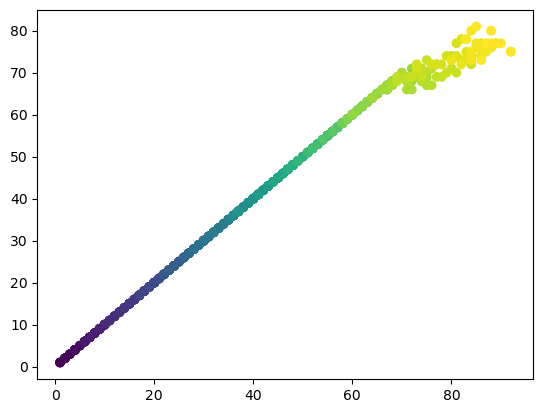

In [45]:
plt.scatter((np.array(res_list['TS_logistic']['tau']) + 1),
            np.array([x.max() for x in res_list['TS_logistic']['regret']]) + np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten(),
           c=np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten())



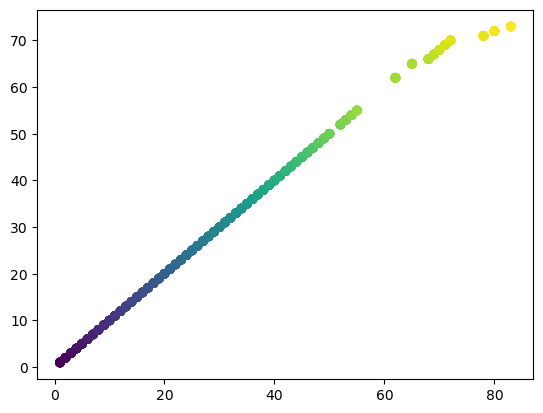

In [20]:
plt.scatter((np.array(res_list['G_logistic']['tau']) + 1),
            np.array([x.max() for x in res_list['G_logistic']['regret']]) + np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten(),
           c=np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten())

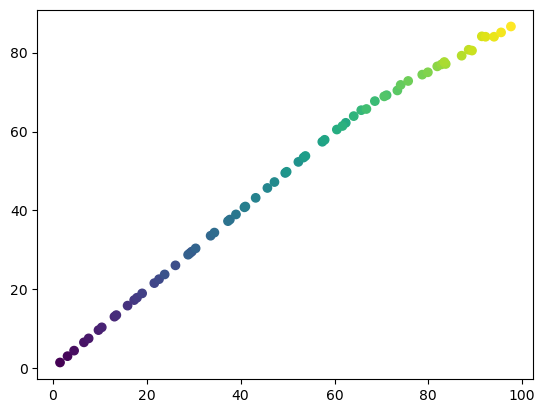

In [25]:
res_df = pd.DataFrame(np.array([(np.array(res_list['Random']['tau']) + 1),
np.array([x.max() for x in res_list['Random']['regret']]),
np.array([np.ones(10) * x for x in np.arange(1,65)]).flatten()]).T).groupby(2).mean().reset_index()

plt.scatter(res_df.loc[:,0],res_df.loc[:,1]+res_df.loc[:,2],c=+res_df.loc[:,2])

In [205]:
g = 13
shape_ = np.array(res_list['TS_logistic']['regret'][-g]).shape
t_argmax = shape_[0] - np.argmax(np.array(res_list['TS_logistic']['regret'][-g])[::-1])
#t_argmax = np.argmax(np.array(res_list['TS_logistic']['regret'][-1]))
(np.diff(np.array(res_list['TS_logistic']['regret'][-g])[t_argmax:])+1).sum()

0

In [237]:
np.array([x.max() for x in res_list['TS_logistic']['regret']])# + 65 #+ 18

array([ 2,  6,  4,  3,  5,  5,  5,  3,  1,  5,  6,  6,  8,  2,  7,  3,  4,
        7,  4,  4,  9,  7,  5,  7, 11, 10,  9, 11, 11, 11,  8, 12,  6, 13,
        9, 16, 12, 10,  3, 13, 15, 10, 12, 15, 14,  9, 14, 12, 12, 14])

In [217]:
np.array([x[-1] for x in res_list['TS_logistic']['regret']])# + 65 + 18

array([ 2,  6,  4,  3,  5,  5,  5,  3,  1,  5,  6,  6,  8,  2,  7,  3,  4,
        7,  4,  4,  9,  7,  5,  7, 11, 10,  9, 11, 11, 11,  8, 12,  6, 13,
        9, 16, 12, 10,  3, 13,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [92]:
t_argmax = np.argmax(np.array(res_list['G_logistic']['regret'][0]))+1
(np.diff(np.array(res_list['G_logistic']['regret'][0])[t_argmax:])+1).sum()
np.array(res_list['G_logistic']['regret'][0])[t_argmax:]

array([2, 2, 2, 2, 2])

In [43]:
#for algo in algos_dict:
#    algo_label = algos_dict[algo][3]
#    algo_style = algos_dict[algo][4]
    #M_ = res_list[algo]['M']
#    y_ = np.mean(res_list[algo]['regret'][-S:], axis = 0) #np.array(res_list[algo]['regret'][-1])
    #y_ = np.array(res_list[algo]['regret'][-1]) #np.array(res_list[algo]['regret'][-1])
    #ci = res_list[algo]['tau_std']+1
#    plt.plot(y_,
#                  algo_style, label=algo_label)
    #plt.fill_between(M_, (y_-ci), (y_+ci), color = algo_style, alpha=.1)

#    plt.legend()

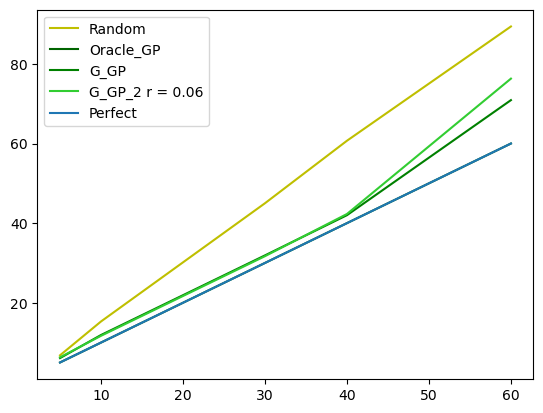

In [53]:
your_keys = ['Random',
             #'Oracle_logistic',
             #'TS_logistic',
             #'G_logistic',
             #'G_logistic_2',
             'Oracle_GP',
             'G_GP',
             'G_GP_2']

algos_dict_2 = {key: algos_dict[key] for key in your_keys}

for algo in algos_dict_2:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    M_ = res_list[algo]['M']
    y_ = np.array(res_list[algo]['tau_mean'])+1 #np.mean(reg_list[algo], axis = 0)[:T]
    #ci = res_list[algo]['tau_std']+1
    plt.plot(M_, y_,
                  algo_style, label=algo_label)
    #plt.fill_between(M_, (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()
    
plt.plot(M_, M_, label='Perfect')
plt.legend()

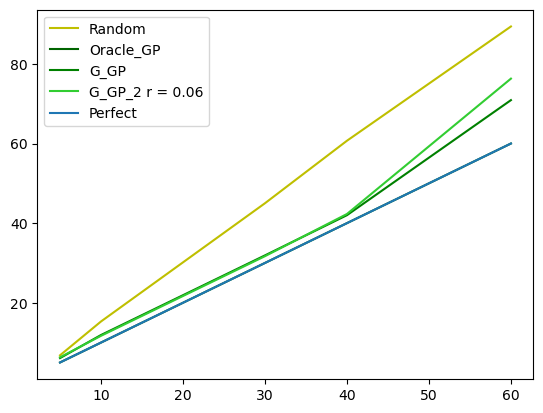

In [53]:
your_keys = ['Random',
             #'Oracle_logistic',
             #'TS_logistic',
             #'G_logistic',
             #'G_logistic_2',
             'Oracle_GP',
             'G_GP',
             'G_GP_2']

algos_dict_2 = {key: algos_dict[key] for key in your_keys}

for algo in algos_dict_2:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    M_ = res_list[algo]['M']
    y_ = np.array(res_list[algo]['tau_mean'])+1 #np.mean(reg_list[algo], axis = 0)[:T]
    #ci = res_list[algo]['tau_std']+1
    plt.plot(M_, y_,
                  algo_style, label=algo_label)
    #plt.fill_between(M_, (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()
    
plt.plot(M_, M_, label='Perfect')
plt.legend()

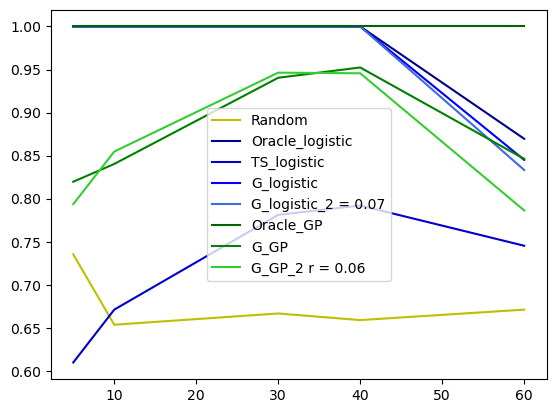

In [50]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    M_ = np.array(res_list[algo]['M'])
    y_ = np.array(res_list[algo]['tau_mean'])+1 #np.mean(reg_list[algo], axis = 0)[:T]
    #ci = res_list[algo]['tau_std']+1
    plt.plot(M_, M_ / y_,
                  algo_style, label=algo_label)
    #plt.fill_between(M_, (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [54]:
from math import factorial
from itertools import permutations 


In [22]:
theta = np.array([1,1])
expit = lambda x: 1/(1+np.exp(-x))
x = np.random.multivariate_normal(np.zeros(2),np.eye(2),10000)
f = x @ theta
p = expit(f) 
y = np.random.binomial(1,p)

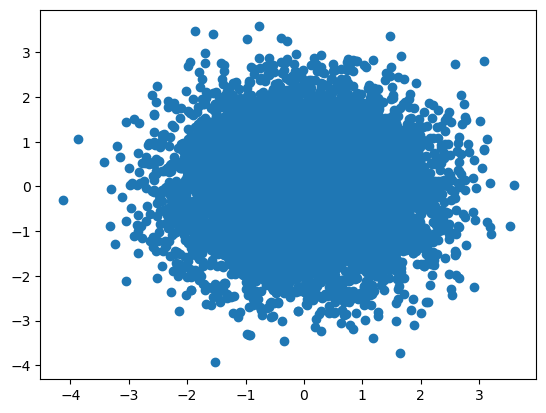

In [10]:
plt.scatter(x[:,0], x[:,1])

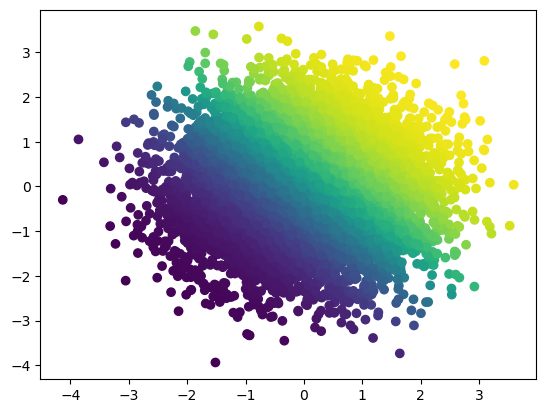

In [11]:
plt.scatter(x[:,0], x[:,1], c=p)

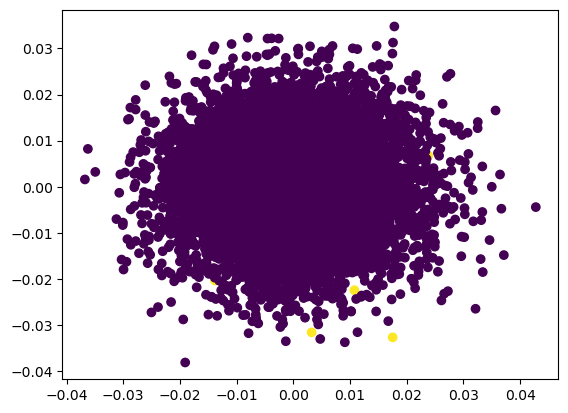

In [37]:
plt.scatter(x[:,0], x[:,1], c=y)

In [12]:
#plt.scatter(x[np.linalg.norm(x, axis=1) > np.quantile(np.linalg.norm(x, axis=1),.8),0],
#           x[np.linalg.norm(x, axis=1) > np.quantile(np.linalg.norm(x, axis=1),.8),1])

In [13]:

#perm = np.array(list(perm))

In [14]:
from sklearn.linear_model import LogisticRegression

In [13]:
theta = np.array([1,1])
expit = lambda x: 1/(1+np.exp(-x))

scores = np.zeros(1000)
for i in range(1000):
    x = np.random.multivariate_normal(np.zeros(2),np.eye(2),15)
    f = x @ theta
    p = expit(f) 
    y = np.random.binomial(1,p)
    clf = LogisticRegression(random_state=0).fit(x, y)
    scores[i] = clf.score(x, y)

NameError: name 'LogisticRegression' is not defined

In [14]:
scores.mean()

0.0

(array([  1.,  25.,  75., 112., 218.,   0., 236., 200., 102.,  31.]),
 array([0.46666667, 0.52      , 0.57333333, 0.62666667, 0.68      ,
        0.73333333, 0.78666667, 0.84      , 0.89333333, 0.94666667,
        1.        ]),
 <BarContainer object of 10 artists>)

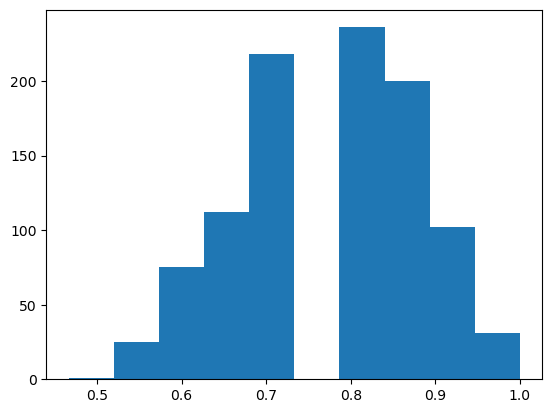

In [17]:
plt.hist(scores)


In [22]:
import bayes_logistic as bl

scores = np.zeros(1000)
for i in range(1000):
    x = np.random.multivariate_normal(np.zeros(2),np.eye(2),15)
    f = x @ theta
    p = expit(f) 
    y = np.random.binomial(1,p)
    
    
    mu_0 = np.zeros(2)
    sigma_0 = np.eye(2)  # to adapt according to the true distribution of theta

    w_posterior, H_posterior = bl.fit_bayes_logistic(y, x, mu_0, sigma_0)
    logistic_prob = bl.logistic_prob(x,w_posterior)
    bayes_logistic_prob = bl.bayes_logistic_prob(x,w_posterior,H_posterior)
    scores[i] = ((bayes_logistic_prob > 0.5) * 1 == y).mean()

In [19]:
perm = permutations(list(range(5))) 
perm = np.array(list(perm))

NameError: name 'permutations' is not defined

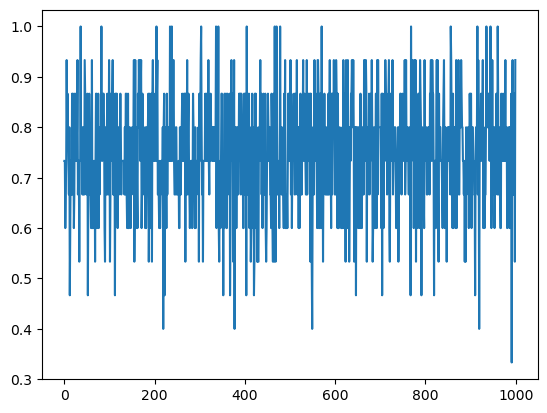

In [23]:
plt.plot(scores)

In [24]:
perm[0,:]

NameError: name 'perm' is not defined

In [173]:
x[perm[0,:],:]

array([[-6.61462405e-01,  1.31600559e-01],
       [ 3.01833243e-01, -3.08882776e-01],
       [ 5.85414057e-01,  3.42472315e-01],
       [ 2.20533261e-02, -1.63246435e-01],
       [-5.06786007e-01,  1.91180178e-01],
       [ 4.77415972e-01,  5.74027107e-01],
       [-4.92277419e-01, -1.08958850e+00],
       [-1.91073363e-03,  1.96619820e+00],
       [-1.09231501e-01, -2.78852065e-01],
       [-9.06871909e-02,  7.55441438e-01]])

In [23]:
x

array([[ 1.36565039, -0.44878888],
       [ 0.78033868, -0.35217818],
       [ 0.49138577, -0.93410006],
       ...,
       [ 0.66083   ,  0.16936308],
       [ 0.06867266,  0.19565751],
       [-1.20357282,  0.18279801]])

In [198]:
perm = permutations(list(range(10))) 
perm = np.array(list(perm))

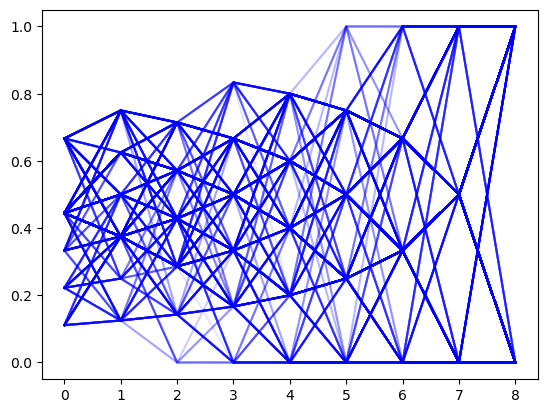

In [200]:
for l in range(1000):
    j = np.random.randint(factorial(10))
    mu_0 = np.zeros(2)
    sigma_0 = np.eye(2)  # to adapt according to the true distribution of theta
    scores = np.zeros(9)
    for i in range(9):

        x_prev = x[perm[j,:(i+1)],:]
        y_prev = y[perm[j,:(i+1)]]

        x_next = x[perm[j,(i+1):],:]
        y_next = y[perm[j,(i+1):]]

        w_posterior, H_posterior = bl.fit_bayes_logistic(y_prev, x_prev, mu_0, sigma_0)
        bayes_logistic_prob = bl.bayes_logistic_prob(x_next,w_posterior,H_posterior)
        scores[i] = ((bayes_logistic_prob > 0.5) * 1 == y_next).mean()

        #print(perm[0,:(i+1)])
        #print(perm[0,(i+1):])
        #clf = LogisticRegression(random_state=0).fit(x[perm[0,:(i+1)],:], y[perm[0,:(i+1)]])
        #scores[i] = 
        #print(clf.score(x[perm[0,(i+1):],:], y[perm[0,(i+1):]]))
    plt.plot(scores, c='b', alpha=.1)

In [164]:
perm = permutations(list(range(5))) 
perm = np.array(list(perm))
for p in perm:
    #plt.plot(y[perm[0]].cumsum())
    #plt.plot(y[list(p)].cumsum(), c='b', alpha=.01)
    

SyntaxError: incomplete input (1502641817.py, line 6)

In [68]:
theta = np.array([1,1])
expit = lambda x: 1/(1+np.exp(-x))
x = np.random.multivariate_normal(np.zeros(2),np.eye(2),100)
f = x @ theta
p = expit(f) 
y = np.random.binomial(1,p)
y[:80] = 1
y[80:] = 0

In [69]:
n_row, n_col = y.shape[0], 1
_, n_desc =  x.shape
cutoff = n_desc
T = n_row
prob_dict = {
    "m": n_row,
    "noise": 0.01,
    "d": cutoff
  }
prob = logistic_discover(**prob_dict)
x = x - x.mean(0)
x = normalize(x, axis=0, norm='l2')
prob.x = x.copy()
prob.y = y.copy()

#prob_GP_dict = {
#    "m": n_row,
#    "noise": 0.01,
#    "d": cutoff
#  }
#prob_GP = GP_discover(**prob_GP_dict)


In [70]:
algos_dict = {
  'Random': [GP_solver, {}, 10, 'Random', 'y']
  #'Oracle_logistic': [Oracle_logistic, {}, 10, 'Oracle_logistic', 'darkblue'],
  #'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'mediumblue'],
  #'G_logistic': [G_logistic, {}, 10, 'G_logistic', 'blue'],
  #'G_logistic_2': [G_logistic, {'r':.08}, 10, 'G_logistic_2 = 0.07', 'royalblue'],
  
  #'Oracle_GP': [TS_GP, {}, 10, 'Oracle_GP', 'darkgreen'],
  #'TS_GP_True': [TS_GP_True, {}, 10, 'TS_GP_True', 'y'],
  #'G_GP': [TS_GP_Rand, {}, 10, 'G_GP', 'green'],
  #'G_GP_2': [TS_GP_Rand, {'r':.06}, 10, 'G_GP_2 r = 0.06', 'limegreen']
  #'Multi_G_GP': [Multi_G_GP, {}, 10, 'Multi_G_GP', 'y']#,
  
}

In [17]:
algos_dict = {
  'Random': [GP_solver, {}, 10, 'Random', 'y'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'mediumblue'],
  'G_logistic': [G_logistic, {}, 10, 'G_logistic', 'blue'],
  'G_logistic_2': [G_logistic, {'r':.08}, 10, 'G_logistic = 0.07', 'royalblue'],
    
  'Oracle_GP': [TS_GP, {}, 10, 'Oracle_GP', 'darkgreen'],
  'G_GP_2': [TS_GP_Rand, {'r':.06}, 10, 'TS_GP_Rand r = 0.06', 'limegreen']
  #'Multi_G_GP': [Multi_G_GP, {}, 10, 'Multi_G_GP', 'y']#,
}



In [28]:
algos_dict = {
  'Random': [GP_solver, {}, 10, 'Random', 'y'],
  'G_logistic': [G_logistic, {}, 10, 'G_logistic', 'blue'],
  'G_logistic_2': [G_logistic, {'r':.08}, 10, 'G_logistic = 0.07', 'royalblue']
}



In [71]:
reg_list = {algo:[] for algo in algos_dict}
#tau_list = {algo:[] for algo in algos_dict}
T = 80
for trial_idx in trange(100):
    t_prob = deepcopy(prob)
    # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, _ = solver.run(T)[:2]
        #act_list[algo].append(getattr(solver, "logistic_discover"))
        #act_list[algo].append(t_prob.actions)
        # print(prob.rewards)
        reg_list[algo].append(reg)
        #tau_list[algo].append(tau)

100%|███████████████████████████████████████| 100/100 [00:00<00:00, 7038.84it/s]


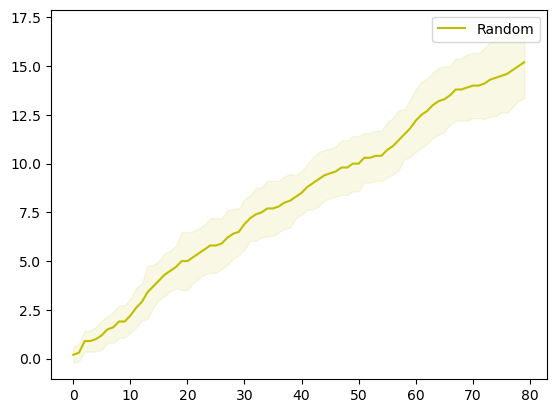

In [72]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [76]:
S = 10
res_list = {algo:defaultdict(list) for algo in algos_dict}

for algo, algo_setup in tqdm(algos_dict.items()):
    for M in [5, 10, 30, 40, 60]:
        taus = np.zeros(S)
        for trial_idx in range(S):
            t_prob = deepcopy(prob)
          
            algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                    # print(algo_func)
            if not trial_idx < algo_N_trials:
                continue
            solver = algo_func(t_prob, **algo_params)
            reg, _, taus[trial_idx] = solver.run(T=T, M=M)
            res_list[algo]['regret'].append(reg)
        
        res_list[algo]['M'].append(M)
        res_list[algo]['tau'].append(taus)   
        res_list[algo]['tau_mean'].append(taus.mean())
        res_list[algo]['tau_std'].append(taus.std())

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00, 29.29it/s]


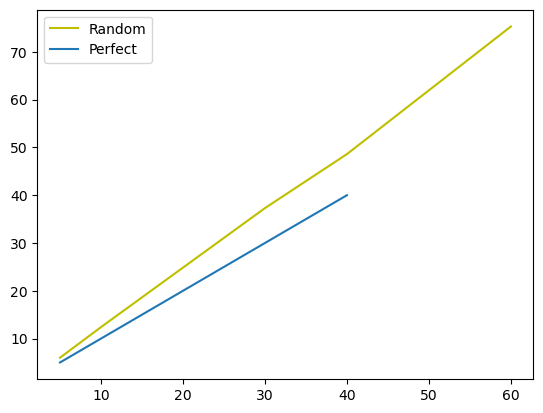

In [77]:
your_keys = ['Random']
             #'Oracle_logistic',
             #'TS_logistic',
             #'G_logistic',
             #'G_logistic_2',
             #'Oracle_GP',
             #'G_logistic']

algos_dict_2 = {key: algos_dict[key] for key in your_keys}

for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    M_ = res_list[algo]['M']
    y_ = np.array(res_list[algo]['tau_mean'])+1 #np.mean(reg_list[algo], axis = 0)[:T]
    #ci = res_list[algo]['tau_std']+1
    plt.plot(M_, y_,
                  algo_style, label=algo_label)
    #plt.fill_between(M_, (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()
    
plt.plot(range(5,41), range(5,41), label='Perfect')
plt.legend()

In [78]:
res_list['Random']['tau'] [5, 10, 30, 40, 60]

[array([4., 4., 4., 7., 5., 4., 6., 7., 4., 5.]),
 array([12., 13.,  9., 11., 12., 12., 10., 11., 10., 14.]),
 array([35., 36., 35., 32., 41., 37., 35., 38., 36., 38.]),
 array([45., 47., 52., 51., 41., 48., 50., 49., 42., 51.]),
 array([77., 73., 74., 78., 74., 70., 73., 75., 76., 73.])]

(array([5., 0., 0., 2., 0., 0., 1., 0., 0., 2.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

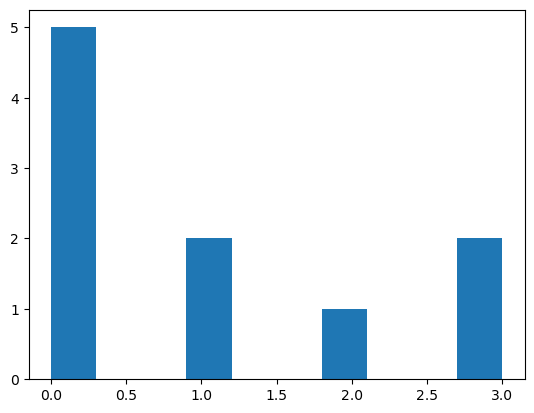

In [89]:
plt.hist(res_list['Random']['tau'][0] + 1 - 5)

(array([1., 0., 2., 0., 2., 0., 3., 0., 1., 1.]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

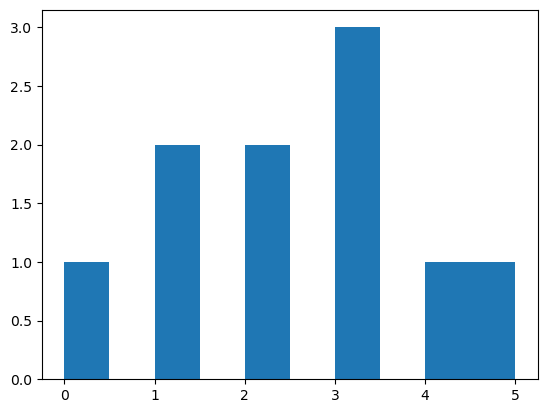

In [90]:
plt.hist(res_list['Random']['tau'][1] + 1 - 10)

(array([1., 0., 0., 3., 2., 1., 2., 0., 0., 1.]),
 array([ 3. ,  3.9,  4.8,  5.7,  6.6,  7.5,  8.4,  9.3, 10.2, 11.1, 12. ]),
 <BarContainer object of 10 artists>)

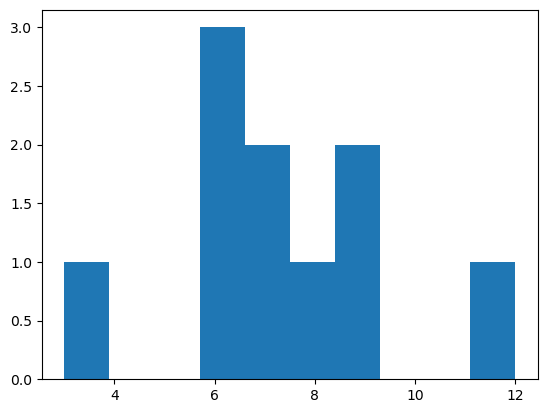

In [91]:
plt.hist(res_list['Random']['tau'][2] + 1 - 30)

(array([2., 0., 0., 1., 0., 1., 1., 1., 1., 3.]),
 array([ 2. ,  3.1,  4.2,  5.3,  6.4,  7.5,  8.6,  9.7, 10.8, 11.9, 13. ]),
 <BarContainer object of 10 artists>)

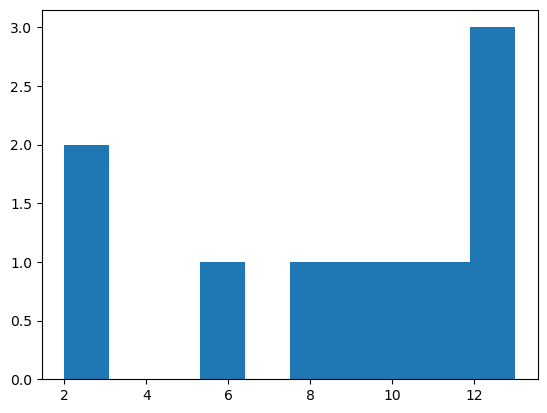

In [92]:
plt.hist(res_list['Random']['tau'][3] + 1 - 40)

(array([1., 0., 0., 3., 0., 2., 1., 1., 1., 1.]),
 array([11. , 11.8, 12.6, 13.4, 14.2, 15. , 15.8, 16.6, 17.4, 18.2, 19. ]),
 <BarContainer object of 10 artists>)

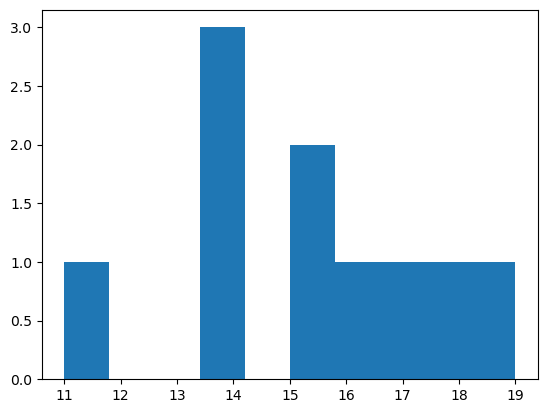

In [93]:
plt.hist(res_list['Random']['tau'][4] + 1 - 60)

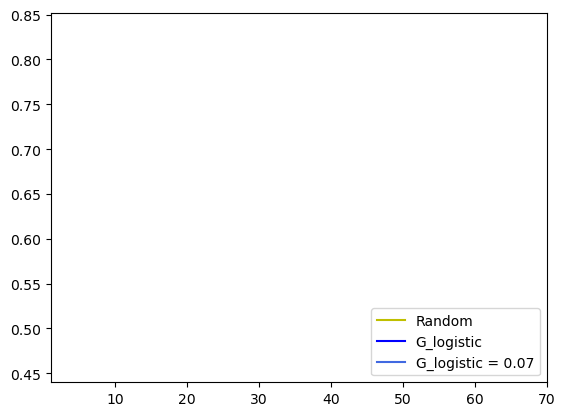

In [35]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    M_ = np.array(res_list[algo]['M'])
    y_ = np.array(res_list[algo]['tau_mean'])+1 #np.mean(reg_list[algo], axis = 0)[:T]
    #ci = res_list[algo]['tau_std']+1
    plt.plot(M_, M_ / y_,
                  algo_style, label=algo_label)
    #plt.fill_between(M_, (y_-ci), (y_+ci), color = algo_style, alpha=.1)
    plt.xlim(1,70)
    plt.legend(loc='lower right')

In [36]:
# import bayes_logistic
import bayes_logistic as bl

mu_0 = np.zeros(2)
sigma_0 = np.eye(2)  # to adapt according to the true distribution of theta
        
w_posterior, H_posterior = bl.fit_bayes_logistic(y, x, mu_0, sigma_0)
logistic_prob = bl.logistic_prob(x,w_posterior)
bayes_logistic_prob = bl.bayes_logistic_prob(x,w_posterior,H_posterior)
((bayes_logistic_prob > 0.5) * 1 == y).mean()

0.8666666666666667

In [37]:
from sklearn.gaussian_process.kernels import RBF
kernel = 1.0 * RBF(1.0)
gpc = GaussianProcessClassifier(kernel=kernel, random_state=0)
gpc.fit(x, y)
#pred = gpc.predict_proba(x)[:,1]
#pred
#(gpc.predict(x) == y).mean()
gpc.score(x, y)

0.9333333333333333

In [38]:
# import bayes_logistic
#import bayes_logistic as bl

mu_0 = np.zeros(5)
sigma_0 = np.eye(5)  # to adapt according to the true distribution of theta
        
w_posterior, H_posterior = bl.fit_bayes_logistic(df_yield.to_numpy().flatten(), (df_desc.to_numpy() - df_desc.to_numpy().mean(0)) / df_desc.to_numpy().std(0), mu_0, sigma_0)
#logistic_prob = bl.logistic_prob(x,w_posterior)
bayes_logistic_prob = bl.bayes_logistic_prob((df_desc.to_numpy() - df_desc.to_numpy().mean(0)) / df_desc.to_numpy().std(0),w_posterior,H_posterior)
((bayes_logistic_prob > 0.5) * 1 == df_yield.to_numpy().flatten()).mean()


0.8585858585858586

In [39]:
gpc.fit((df_desc.to_numpy() - df_desc.to_numpy().mean(0)) / df_desc.to_numpy().std(0), df_yield)
#pred = gpc.predict_proba(x)[:,1]
#pred
#(gpc.predict(x) == y).mean()
gpc.score((df_desc.to_numpy() - df_desc.to_numpy().mean(0)) / df_desc.to_numpy().std(0), df_yield)

1.0

In [94]:
from sklearn.linear_model import LinearRegression

In [95]:
N = 1000
theta = np.array([2,3,-4])
expit = lambda x: 1/(1+np.exp(-x))
x = np.random.multivariate_normal(np.zeros(2),np.eye(2)+np.ones((2,2))*.5,N)
x_ = np.concatenate([np.ones((N,1)), x],axis=1)
#f = x @ theta
#p = expit(f) 
y = x_ @ theta + np.random.normal(size=N)#np.random.binomial(1,p)

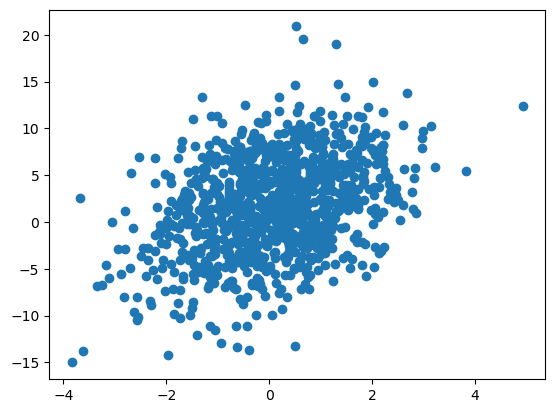

In [96]:
plt.scatter(x[:,0], y)

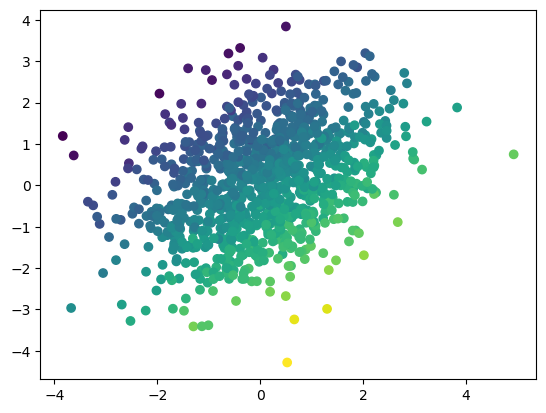

In [97]:
plt.scatter(x[:,0], x[:,1], c=y)

In [98]:
idx = np.random.choice(N, size=2, replace=False)
x_t = x[idx,:]
y_t = y[idx]

In [99]:
reg = LinearRegression().fit(x_t, y_t)
y_hat = reg.predict(x)

In [100]:
np.power(y -y_hat, 2).mean()

27.01053251483476

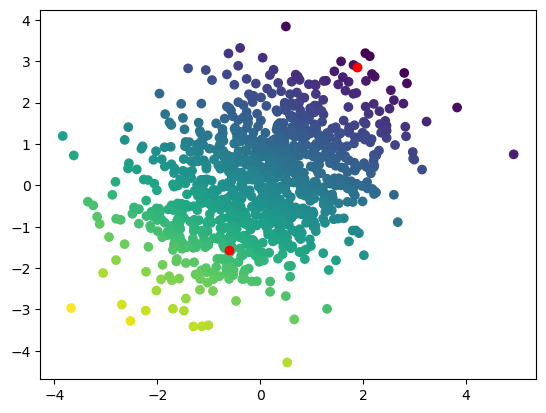

In [101]:
plt.scatter(x[:,0], x[:,1], c=y_hat)
plt.scatter(x_t[:,0], x_t[:,1], c='r')

In [102]:
j = list(range(10))
x_t = x[j]
y_t = y[j]

i = [11]
x_t_1 = x[i]
#y_t = y[j]

reg = LinearRegression().fit(x_t, y_t)
y_t_1_hat = reg.predict(x_t_1)

In [103]:
y_t_1_hat

array([2.212058])

In [104]:
reg = LinearRegression().fit(np.concatenate([x_t, x_t_1]), 
                             np.concatenate([y_t, y_t_1_hat]))
reg.predict(x_t_1)

array([2.212058])

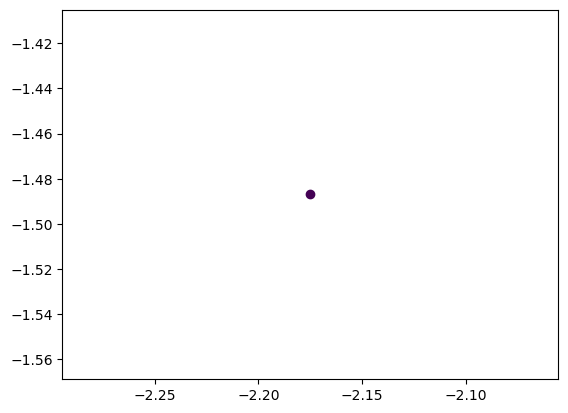

In [105]:
plt.scatter(x_t_1[:,0], x_t_1[:,1], c=y_t_1_hat)

In [106]:
def leverage1(x, j, i):
    n = len(i)
    p = x.shape[1]
    Sig = np.cov(x[j,:].T)
    mu = np.mean(x[j,:], axis=0)
    
    return ((x[i,:].reshape((n,1,p)) - mu) @ Sig @ (x[i,:].reshape((n,p,1))- mu.reshape((p,1)))).reshape(n)

In [107]:
def leverage2(x, j, i):
    n = len(i)
    p = x.shape[1]
    Sig = np.cov(x.T)
    mu = np.mean(x, axis=0)
    
    return ((x[i,:].reshape((n,1,p)) - mu) @ Sig @ (x[i,:].reshape((n,p,1))- mu.reshape((p,1)))).reshape(n)

In [108]:
def leverage3(x, j, i):
    n = len(i)
    p = x.shape[1]
    Sig = np.cov(x[j+i,:].T)
    mu = np.mean(x[j+i,:], axis=0)
    
    return ((x[i,:].reshape((n,1,p)) - mu) @ Sig @ (x[i,:].reshape((n,p,1))- mu.reshape((p,1)))).reshape(n)

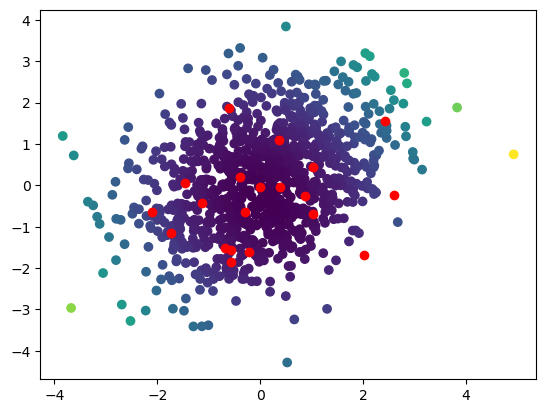

In [109]:
j = list(np.random.choice(500, 20, replace=False))
i = list(np.setdiff1d(list(range(1000)),j))
lev = leverage1(x, j, i)
plt.scatter(x[i,0], x[i,1], c=lev)
plt.scatter(x[j,0], x[j,1], c='r')

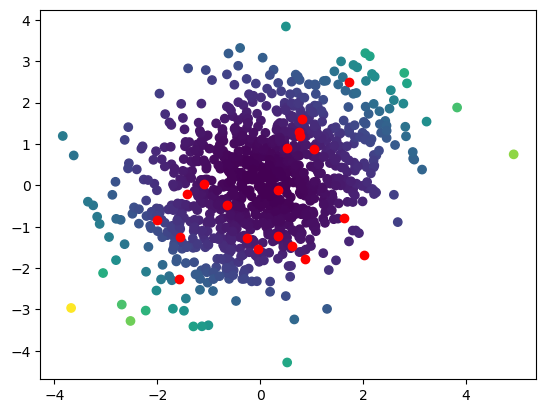

In [110]:
j = list(np.random.choice(500, 20, replace=False))
i = list(np.setdiff1d(list(range(1000)),j))
lev = leverage2(x, j, i)
plt.scatter(x[i,0], x[i,1], c=lev)
plt.scatter(x[j,0], x[j,1], c='r')

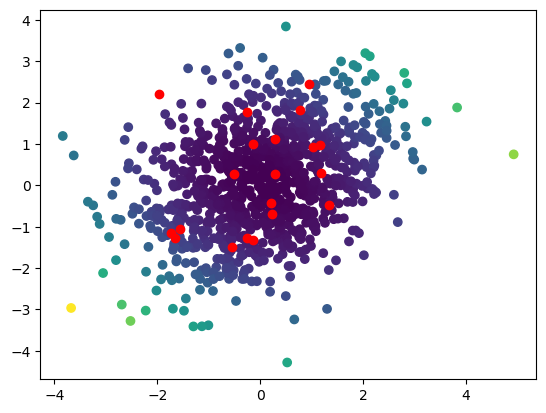

In [111]:
j = list(np.random.choice(500, 20, replace=False))
i = list(np.setdiff1d(list(range(1000)),j))
lev = leverage3(x, j, i)
plt.scatter(x[i,0], x[i,1], c=lev)
plt.scatter(x[j,0], x[j,1], c='r')

In [112]:
def influence1(x, j, i):
        
    P = x_ @ np.linalg.inv(x_.T @ x_) @ x_.T
    
    return P[i,i]

In [285]:
def influence2(x, j, i):
    
    n = len(i)
    infl = np.zeros(n)
    for k, l in enumerate(i):
        P = x_[j + [l],:] @ np.linalg.inv(x_[j + [l],:].T @ x_[j + [l],:]) @ x_[j + [l],:].T
        infl[k] = P[-1,-1]
    
    return infl

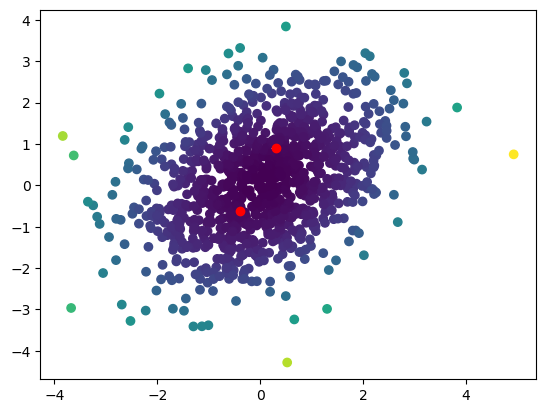

In [114]:
j = list(np.random.choice(500, 2, replace=False))
i = list(np.setdiff1d(list(range(1000)),j))
infl = influence1(x, j, i)
plt.scatter(x[i,0], x[i,1], c=infl)
plt.scatter(x[j,0], x[j,1], c='r')

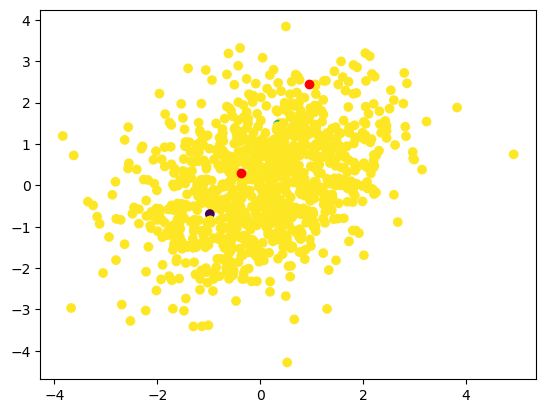

In [115]:
j = list(np.random.choice(500, 2, replace=False))
i = list(np.setdiff1d(list(range(1000)),j))
infl = influence2(x, j, i)
plt.scatter(x[i,0], x[i,1], c=infl)
plt.scatter(x[j,0], x[j,1], c='r')

In [116]:
x_t = x[j]
y_t = y[j]

#i = [11]
x_t_1 = x[i]
#y_t = y[j]

reg = LinearRegression().fit(x_t, y_t)
y_t_1_hat = reg.predict(x_t_1)

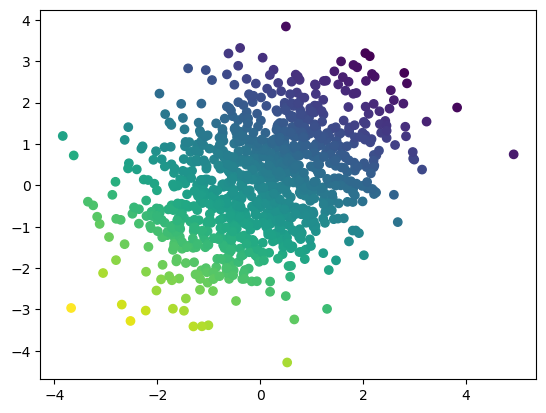

In [117]:
plt.scatter(x[i,0], x[i,1], c=y_t_1_hat + 10*infl)

In [118]:
y_t_1_hat + 10*infl

array([ 7.05767526,  8.12579029,  8.77480377,  6.83240974,  6.21013771,
       10.51015239,  4.72593784, 10.50235161, 12.30717024,  5.80578646,
       11.02881486, 13.04925556, 12.59595273,  8.7598566 , 10.39871611,
        8.28120157,  9.69605613,  7.19632771, 10.59209674, 13.08600845,
       10.64910853,  7.23754106,  6.29856669,  8.44321085,  7.3932187 ,
        7.72909699,  9.42039366,  9.71314893,  6.71856163,  7.75240633,
       10.82985638, 11.81463105,  9.3352095 , 10.50827012, 11.89721473,
        5.04868628,  7.71652578,  9.58873666, 12.7875645 , 12.19303758,
        9.95797985, 10.19064479, 11.95615212,  8.26993418,  9.24113522,
       12.10377683, 12.42163082,  8.70587058,  8.53349787,  9.47318772,
        6.63324261,  8.98119837,  7.5928068 ,  5.64902805,  7.5655893 ,
        9.25425809,  9.91931952,  9.91173254, 11.67044956,  9.18778378,
       10.61620318,  5.38972475,  7.75290248,  8.44940821, 12.56866899,
        8.10283546, 10.77349236,  6.64675673,  8.95464379,  7.81

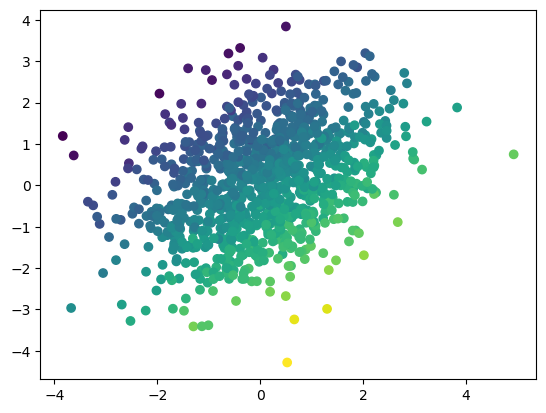

In [119]:
plt.scatter(x[:,0], x[:,1], c=y)

In [120]:
theta

array([ 2,  3, -4])

In [121]:
reg.coef_

array([-0.86196682, -1.40584535])

In [122]:
reg.intercept_

-0.9159673141663607

In [123]:
from scipy.stats import multivariate_normal

In [124]:
n_mix = 4
S_list = []
rv_list = []
size_list = [600,200,150,50]
mean_list = [[20,20],[-20,-20],[-20,20],[20,-20]]
sigma_list = [.7,.8,.5,.7]

for i in range(n_mix):
    mui = mean_list[i]
    sigmai = sigma_list[i]*np.eye(2)
    Si = np.random.multivariate_normal(mui, sigmai, size_list[i])
    rvi = multivariate_normal(mean=mui, cov=sigmai) 
    pdfi = rvi.pdf(Si)
    #Si = np.concatenate([Si, i*np.ones((size_list[i],1)), pdfi.reshape((size_list[i],1))], axis=1)
    rv_list.append(rvi)
    S_list.append(Si)
    
S = np.concatenate(S_list)

In [125]:
S

array([[ 19.40031117,  22.68429792],
       [ 19.4710229 ,  18.36187743],
       [ 20.51963778,  19.62300964],
       ...,
       [ 20.4669489 , -18.48808736],
       [ 21.45947714, -20.99801774],
       [ 19.64135173, -19.18816421]])

In [276]:
N = 1000
p = 50
theta = 5*np.random.rand(p+1)
expit = lambda x: 1/(1+np.exp(-x))
x = np.random.multivariate_normal(np.zeros(p),np.eye(p)+np.ones((p,p))*.5,N)
#x = S
x_ = np.concatenate([np.ones((N,1)), x],axis=1)
#f = x @ theta
#p = expit(f) 
y = x_ @ theta + 5* np.random.normal(size=N)#np.random.binomial(1,p)

In [133]:
np.power(np.array([reg.intercept_] + list(reg.coef_)) - theta, 2).mean()

7.910883542010619

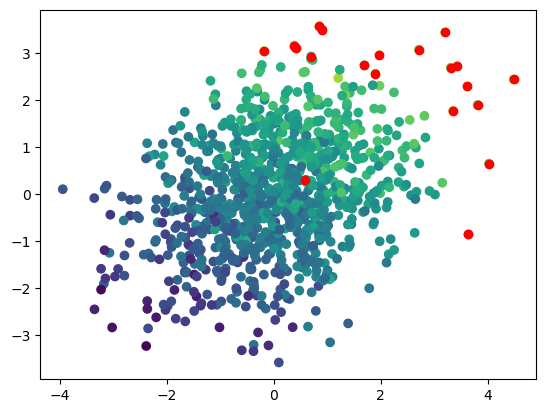

In [229]:
plt.scatter(x[:,0],x[:,1],c=y)
plt.scatter(x[j,0],x[j,1],c='r')

In [331]:
list(np.random.choice(500, 2, replace=False))

[204, 270]

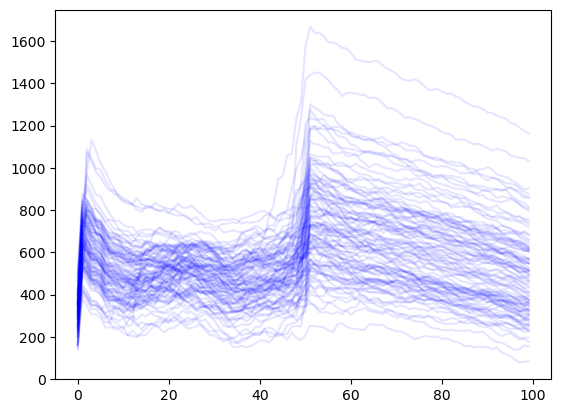

In [342]:
y_res = np.zeros((100,100))
for k in range(100):
    T = 98
    j = list(np.random.choice(500, 2, replace=False)) #[262, 783]
    alpha = 1
    for t in range(T):

        i = list(np.setdiff1d(list(range(1000)),j))
        #infl = influence2(x, j, i)
        x_t = x[j]
        y_t = y[j]

        x_t_1 = x[i]

        reg = LinearRegression().fit(x_t, y_t)
        y_t_1_hat = reg.predict(x_t_1)

        i_t = np.argmax(alpha*y_t_1_hat)# + (1-alpha) * infl)
        #i_t = np.argmax(y_t_1_hat)
        A_t = i[i_t]
        #print(np.max(y_t_1_hat), y[A_t])
        #print(np.power(np.array([reg.intercept_] + list(reg.coef_)) - theta, 2).mean())
        j = j + [A_t]
    
    y_ = y.copy()
    y_[::-1].sort()
    y_res[k,:] = y_[:100].cumsum()-y[j].cumsum()
    plt.plot(y_res[k,:], c='blue', alpha=.1)

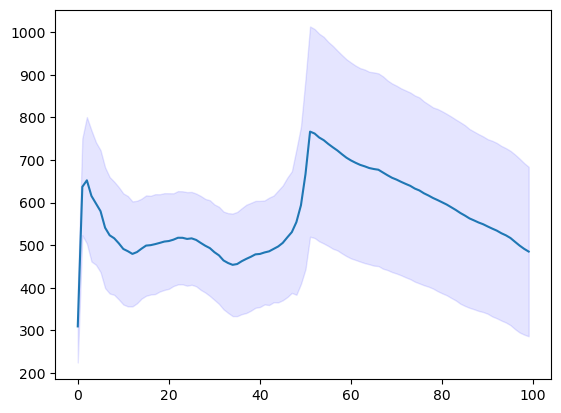

In [343]:
plt.plot(y_res.mean(0))
#plt.plot(y_res.mean(0)-y_res.std(0))
plt.fill_between(range(100), y_res.mean(0)-y_res.std(0), y_res.mean(0)+y_res.std(0), color = 'b', alpha=.1)

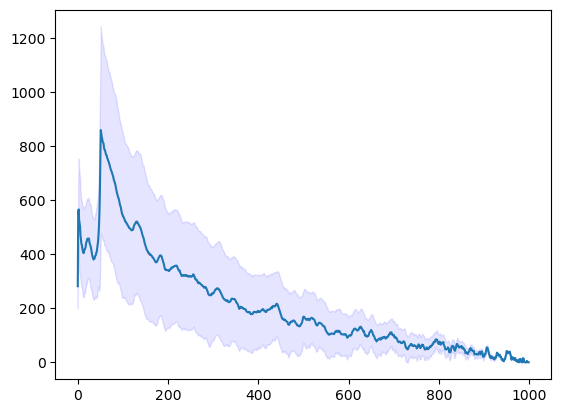

In [340]:
plt.plot(y_res.mean(0))
#plt.plot(y_res.mean(0)-y_res.std(0))
plt.fill_between(range(100), y_res.mean(0)-y_res.std(0), y_res.mean(0)+y_res.std(0), color = 'b', alpha=.1)

In [318]:
#plt.scatter(x[:,0], x[:,1], c=y)
#plt.scatter(x[j,0], x[j,1], c='r')

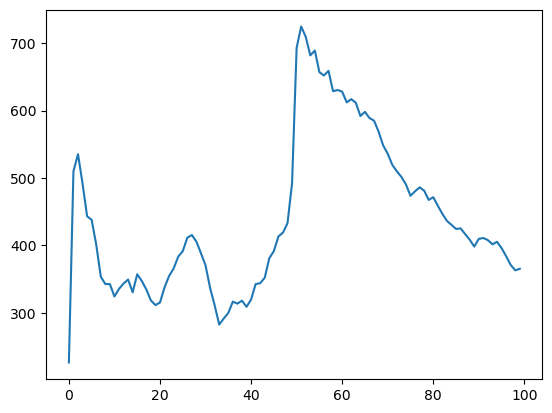

In [345]:
y_ = y.copy()
y_[::-1].sort()
plt.plot(y_[:100].cumsum()-y[j].cumsum())
#plt.plot(y[j].cumsum(),c='r')

In [302]:
T = 100
j_1 = []#list(np.random.choice(500, 2, replace=False))
#alpha = 1
for t in range(T):
    #print(j_1)
    alpha = (t/(T-1))**1
    i = list(np.setdiff1d(list(range(1000)),j_1))
    if len(j_1)>=2:
        infl = leverage3(x, j_1, i)
        x_t = x[j_1]
        y_t = y[j_1]

        x_t_1 = x[i]

        reg = LinearRegression().fit(x_t, y_t)
        y_t_1_hat = reg.predict(x_t_1)
        #print(alpha)
        i_t = np.argmax(alpha*y_t_1_hat + (1-alpha) * infl)
        A_t = i[i_t]
        #print(np.max(y_t_1_hat), y[A_t])
        print(alpha, np.power(np.array([reg.intercept_] + list(reg.coef_)) - theta, 2).mean())
        j_1 = j_1 + [A_t]
    else:
        j_1.append(np.argmax(influence1(x, j_1, i)))

0.020202020202020204 38.72482191225795
0.030303030303030304 3.1756818881297817
0.04040404040404041 5.282456129547577
0.050505050505050504 2.515085368460225
0.06060606060606061 4.16615302369653
0.0707070707070707 4.271573902985187
0.08080808080808081 4.537008785610817
0.09090909090909091 3.1659339989572985
0.10101010101010101 2.1136575622652485
0.1111111111111111 1.5566185049208188
0.12121212121212122 1.4572314175242747
0.13131313131313133 1.36143362848414
0.1414141414141414 1.361383242428912
0.15151515151515152 1.3299989982385563
0.16161616161616163 1.182620810723515
0.1717171717171717 1.1910774593173012
0.18181818181818182 1.1896495961021305
0.1919191919191919 1.1858862904168448
0.20202020202020202 1.180644128293349
0.21212121212121213 1.1883950345139471
0.2222222222222222 1.1645333227189294
0.23232323232323232 1.1037317093887997
0.24242424242424243 1.0621462056460715
0.25252525252525254 1.0630644167634231
0.26262626262626265 1.0041430939923335
0.2727272727272727 0.9788127732962071
0.

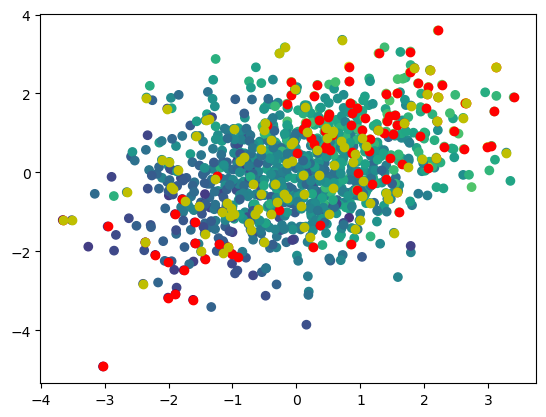

In [310]:
plt.scatter(x[:,0], x[:,1], c=y)
plt.scatter(x[j_1,0], x[j_1,1], c='r')
plt.scatter(x[j,0], x[j,1], c='y')

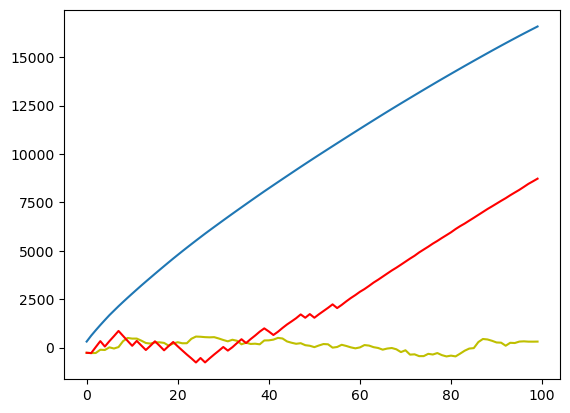

In [311]:
y_ = y.copy()
y_[::-1].sort()
plt.plot(y_[:100].cumsum())
plt.plot(y[j].cumsum(),c='y')
plt.plot(y[j_1].cumsum(),c='r')

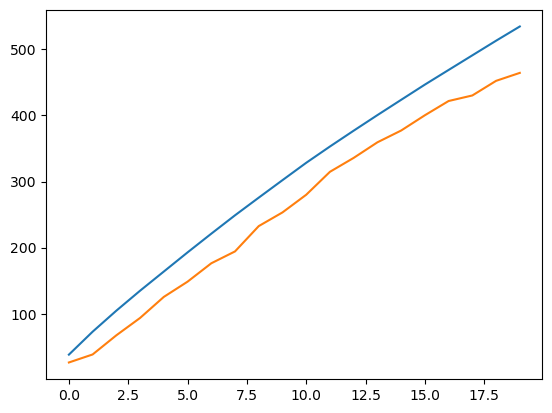

In [179]:
y_ = y.copy()
y_[::-1].sort()
plt.plot(y_[:20].cumsum())
plt.plot(y[j].cumsum())